# Demostración: Detección de Anomalías en un Proceso Electoral Simulado

> **Descargo ético obligatorio:**
> *Todos los votos de este proyecto son simulados. Los departamentos y municipios son reales de Colombia, pero los resultados, las mesas y los candidatos son ficticios: no representan ninguna elección real ni hacen afirmaciones sobre ella. Una alerta indica una inconsistencia que merece revisión, no una prueba de fraude.*


## 1. Cargar el dataset simulado y las dependencias del proyecto

In [1]:
import sys
from pathlib import Path
# Asegurar que la raíz del proyecto esté en sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

import pandas as pd
from IPython.display import Image, display
from src.config import DATA_RAW_CSV, DATA_PROCESSED_CSV, OUTPUTS_FIG_DIR, OUTPUTS_TAB_DIR, SEED
from src.generate_dataset import generar_dataset
from src.features import agregar_features
from src.rules import aplicar_reglas
from src.isolation_forest import aplicar_isolation_forest
from src.evaluate import ejecutar_evaluacion

# Cargar o regenerar dataset
df_raw = pd.read_csv(DATA_RAW_CSV) if DATA_RAW_CSV.exists() else generar_dataset(seed=SEED)
print(f"Total de mesas cargadas: {len(df_raw)}")
df_raw.head()

Total de mesas cargadas: 5000


,mesa_id,departamento,municipio,zona,puesto,votantes_habilitados,votos_cand_A,votos_cand_B,votos_cand_C,votos_cand_D,votos_blanco,votos_nulos,votos_no_marcados,total_votos_reportado,hora_reporte,es_anomalia,tipo_anomalia,nota_simulacion
0,M00001,Antioquia,Medellín,urbana,Medellín · Puesto 01,396,68,42,11,6,1,2,1,131,2026-09-13T17:15:00,0,ninguna,NaN
1,M00002,Antioquia,Medellín,urbana,Medellín · Puesto 01,590,153,66,28,22,6,5,0,280,2026-09-13T16:18:00,0,ninguna,NaN
2,M00003,Antioquia,Medellín,urbana,Medellín · Puesto 01,523,120,72,15,27,3,1,0,238,2026-09-13T17:20:00,0,ninguna,NaN
3,M00004,Antioquia,Medellín,rural,Medellín · Puesto 01,268,52,31,12,1,2,1,0,99,2026-09-13T18:26:00,0,ninguna,NaN
4,M00005,Antioquia,Medellín,urbana,Medellín · Puesto 01,472,2,426,2,1,2,2,2,437,2026-09-13T16:53:00,1,voto_unanime,NaN


## 2. Aplicar Ingeniería de Características (Features) y Reglas Simples

In [2]:
df_feat = agregar_features(df_raw)
df_reglas = aplicar_reglas(df_feat)
print(f"Mesas alertadas por reglas simples: {df_reglas['alerta_reglas'].sum()}")
df_reglas['severidad_reglas'].value_counts()

Mesas alertadas por reglas simples: 190


severidad_reglas
sin alerta    4810
critica         76
alta            58
media           56
Name: count, dtype: int64

## 3. Aplicar Detección no supervisada con Isolation Forest

In [3]:
df_proc, modelo_if, scaler = aplicar_isolation_forest(df_reglas, seed=SEED)
print(f"Mesas alertadas por Isolation Forest (top 4% outliers): {df_proc['alerta_if'].sum()}")
df_proc[['mesa_id', 'participacion', 'pct_max_candidato', 'score_if', 'alerta_if', 'ranking_if']].head()

Mesas alertadas por Isolation Forest (top 4% outliers): 200


,mesa_id,participacion,pct_max_candidato,score_if,alerta_if,ranking_if
0,M00001,0.330808,0.535433,0.428557,False,1618
1,M00002,0.474576,0.568773,0.412174,False,2444
2,M00003,0.455067,0.512821,0.410409,False,2555
3,M00004,0.369403,0.541667,0.422583,False,1866
4,M00005,0.925847,0.988399,0.665315,True,29


## 4. Evaluación contra Ground Truth y Métricas de Clasificación

In [4]:
df_final, tablas = ejecutar_evaluacion(df_proc)
display(tablas['metricas'])
display(tablas['recall_tipo'])

EVALUACIÓN DE DETECTORES (GROUND TRUTH)
            detector  mesas_alertadas  VP  FP  precision  recall       f1
      Reglas simples              190 188   2   0.989474   0.940 0.964103
    Isolation Forest              200 125  75   0.625000   0.625 0.625000
  Unión (Cualquiera)              275 199  76   0.723636   0.995 0.837895
Intersección (Ambas)              115 114   1   0.991304   0.570 0.723810

Recall por tipo de anomalía:
            tipo_anomalia  recall_reglas  recall_if  recall_union
      sobre_participacion       1.000000   0.700000      1.000000
            relleno_urnas       0.733333   0.844444      0.977778
             voto_unanime       1.000000   1.000000      1.000000
inconsistencia_aritmetica       1.000000   0.342857      1.000000
         numeros_redondos       1.000000   0.080000      1.000000
          nulos_excesivos       1.000000   0.566667      1.000000

Falsos positivos en casos extremos legítimos (40 mesas):
            detector  falsos_positivos  

,detector,mesas_alertadas,VP,FP,FN,VN,precision,recall,f1
0,Reglas simples,190,188,2,12,4798,0.989474,0.940,0.964103
1,Isolation Forest,200,125,75,75,4725,0.625000,0.625,0.625000
2,Unión (Cualquiera),275,199,76,1,4724,0.723636,0.995,0.837895
3,Intersección (Ambas),115,114,1,86,4799,0.991304,0.570,0.723810


,tipo_anomalia,total_inyectadas,recall_reglas,recall_if,recall_union,recall_interseccion
0,sobre_participacion,30,1.000000,0.700000,1.000000,0.700000
1,relleno_urnas,45,0.733333,0.844444,0.977778,0.600000
2,voto_unanime,35,1.000000,1.000000,1.000000,1.000000
3,inconsistencia_aritmetica,35,1.000000,0.342857,1.000000,0.342857
4,numeros_redondos,25,1.000000,0.080000,1.000000,0.080000
5,nulos_excesivos,30,1.000000,0.566667,1.000000,0.566667


## 5. Visualizaciones Oficiales del Proceso

=== fig1_distribucion_participacion.png ===


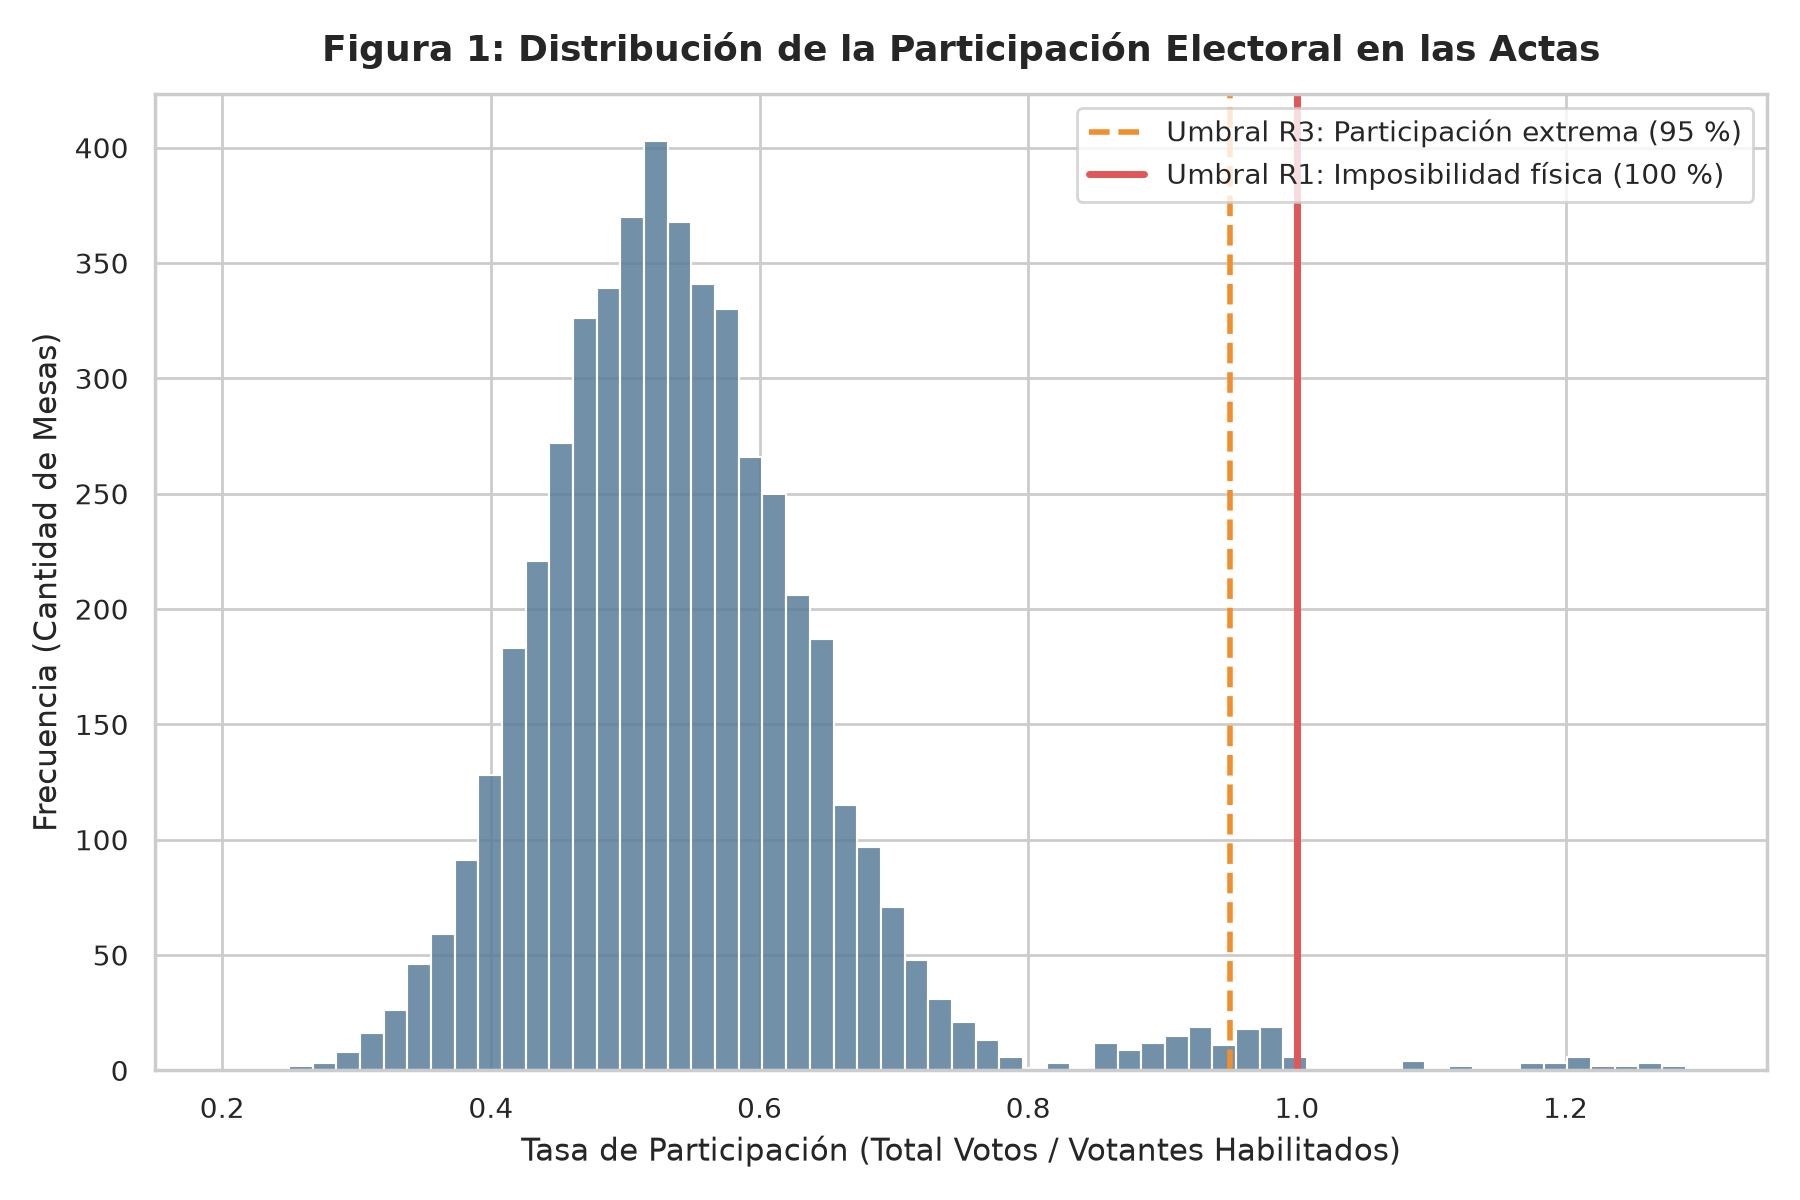

=== fig2_huella_electoral.png ===


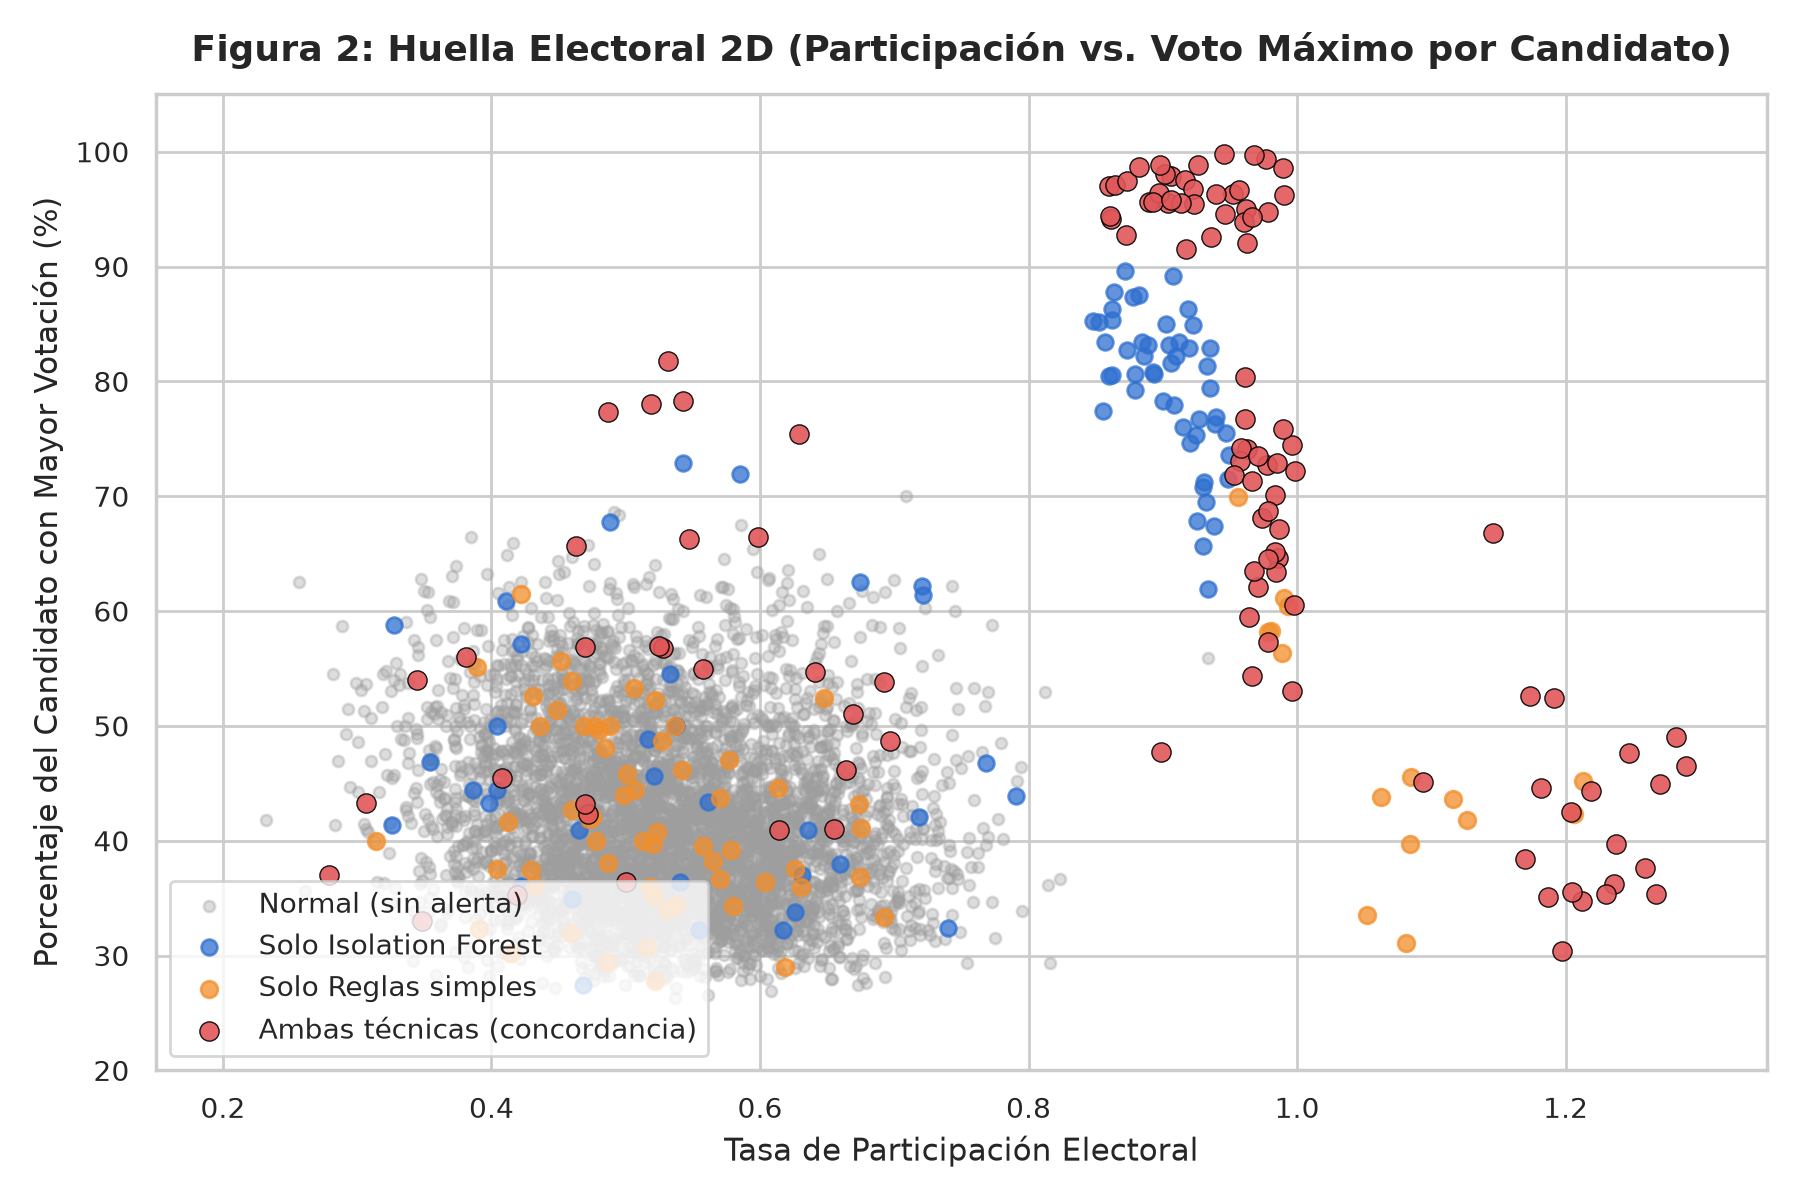

=== fig3_score_isolation_forest.png ===


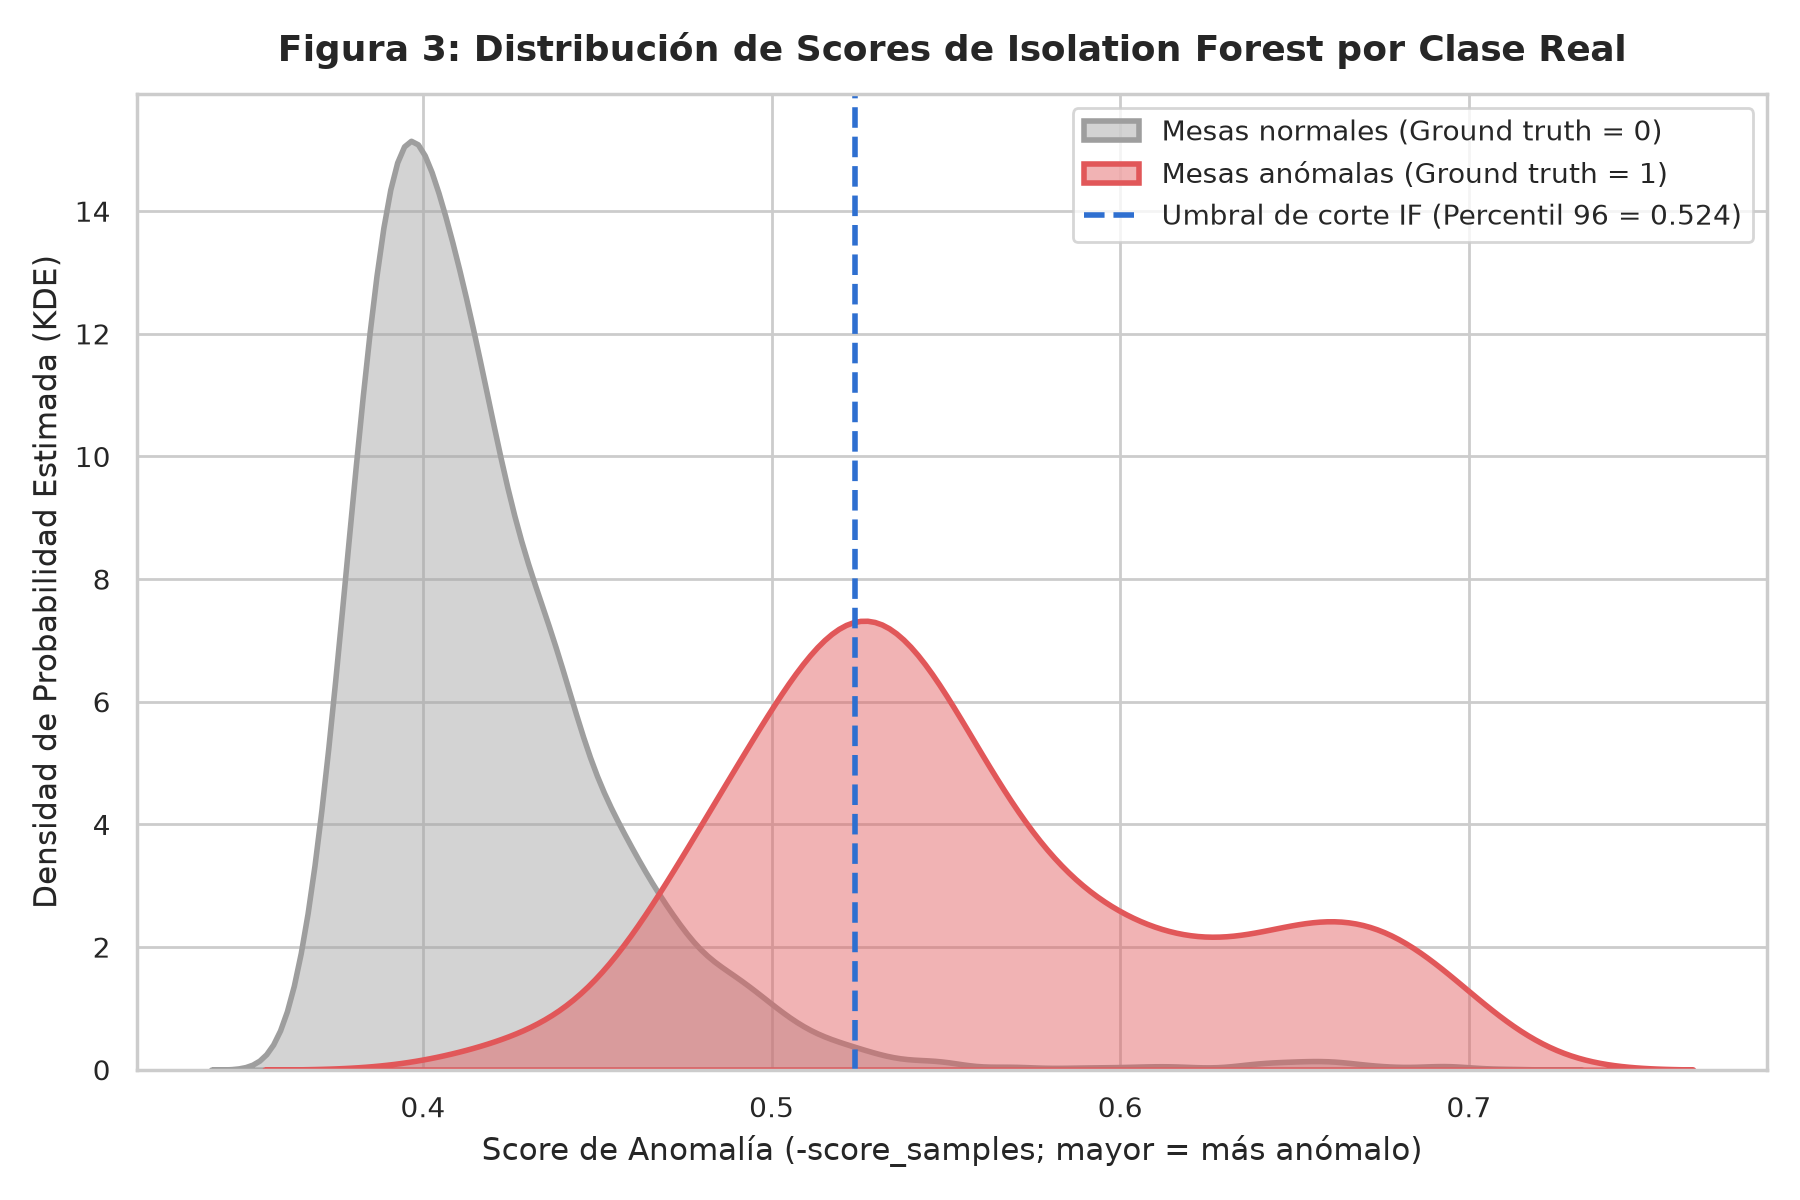

=== fig4_recall_por_tipo.png ===


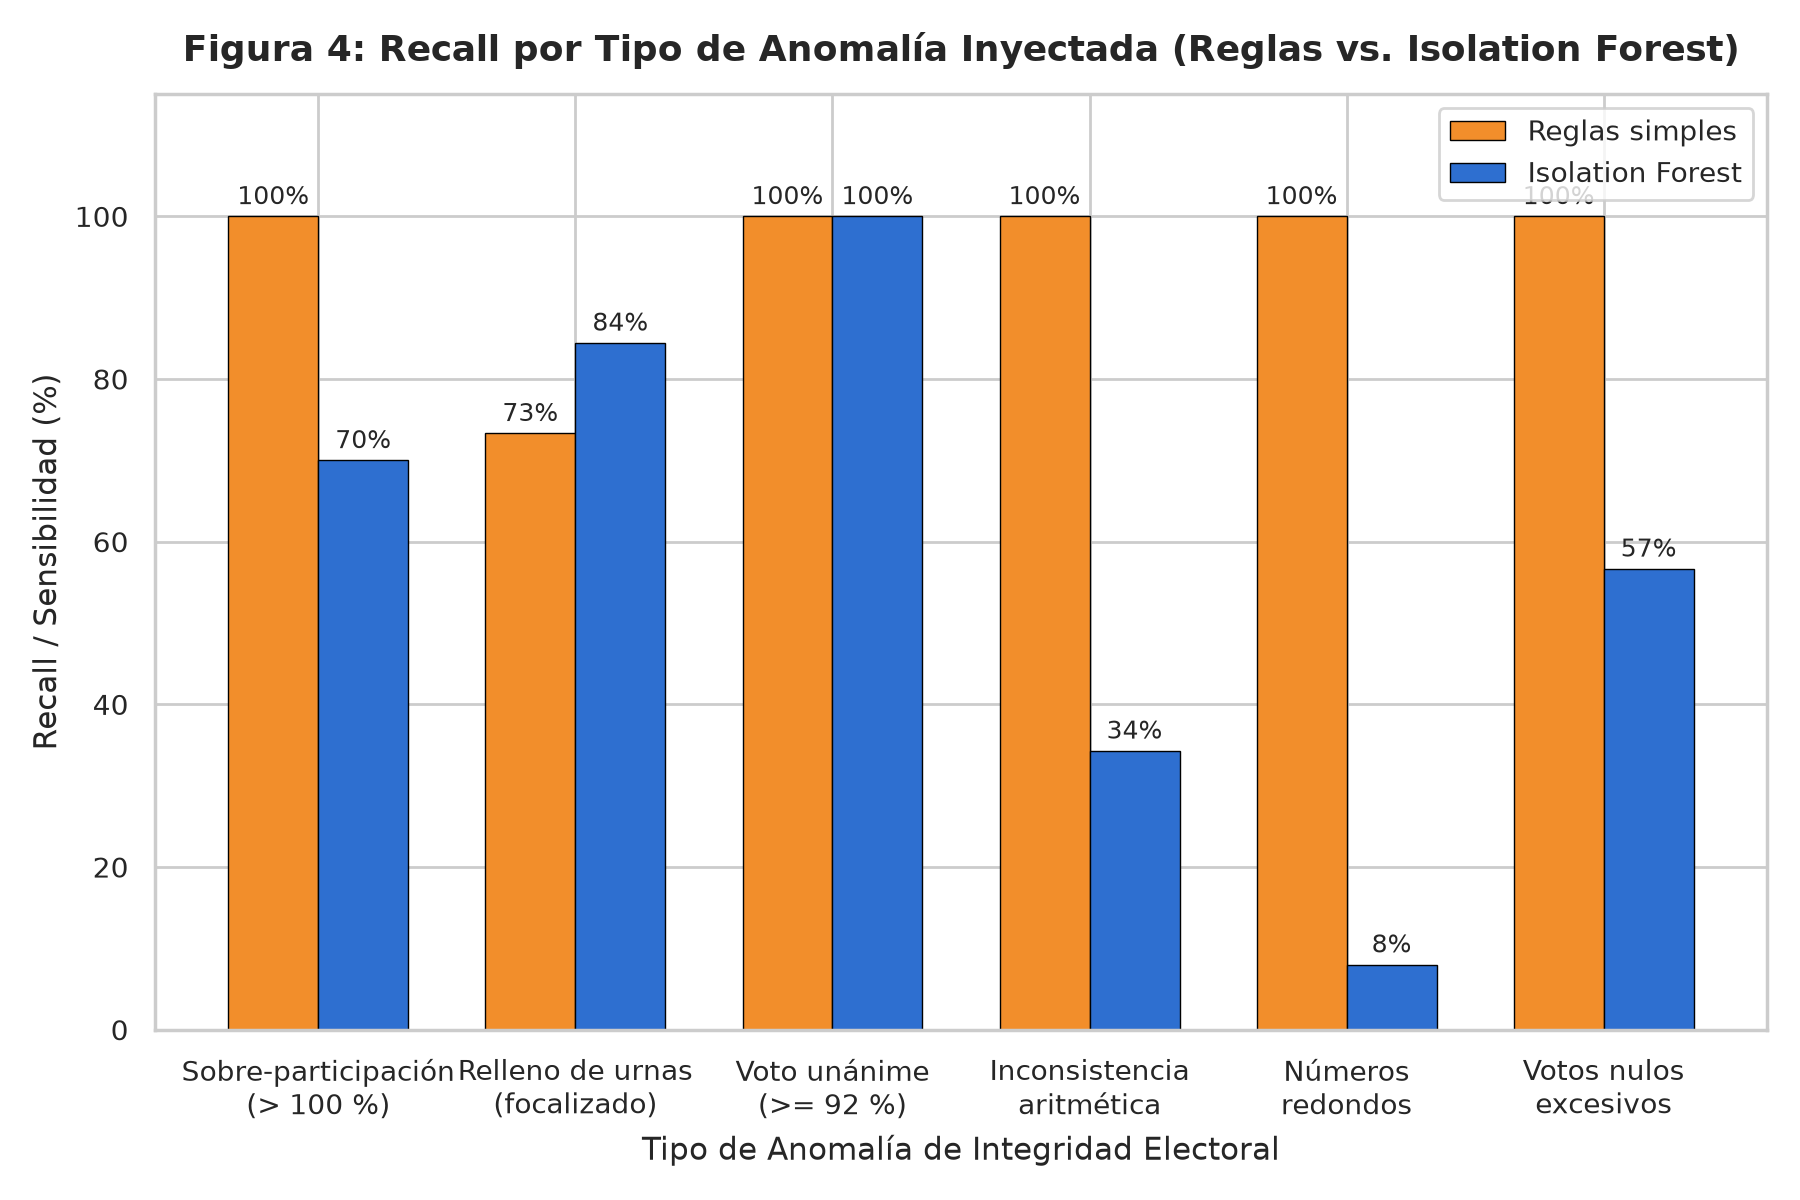

=== fig5_riesgo_por_municipio.png ===


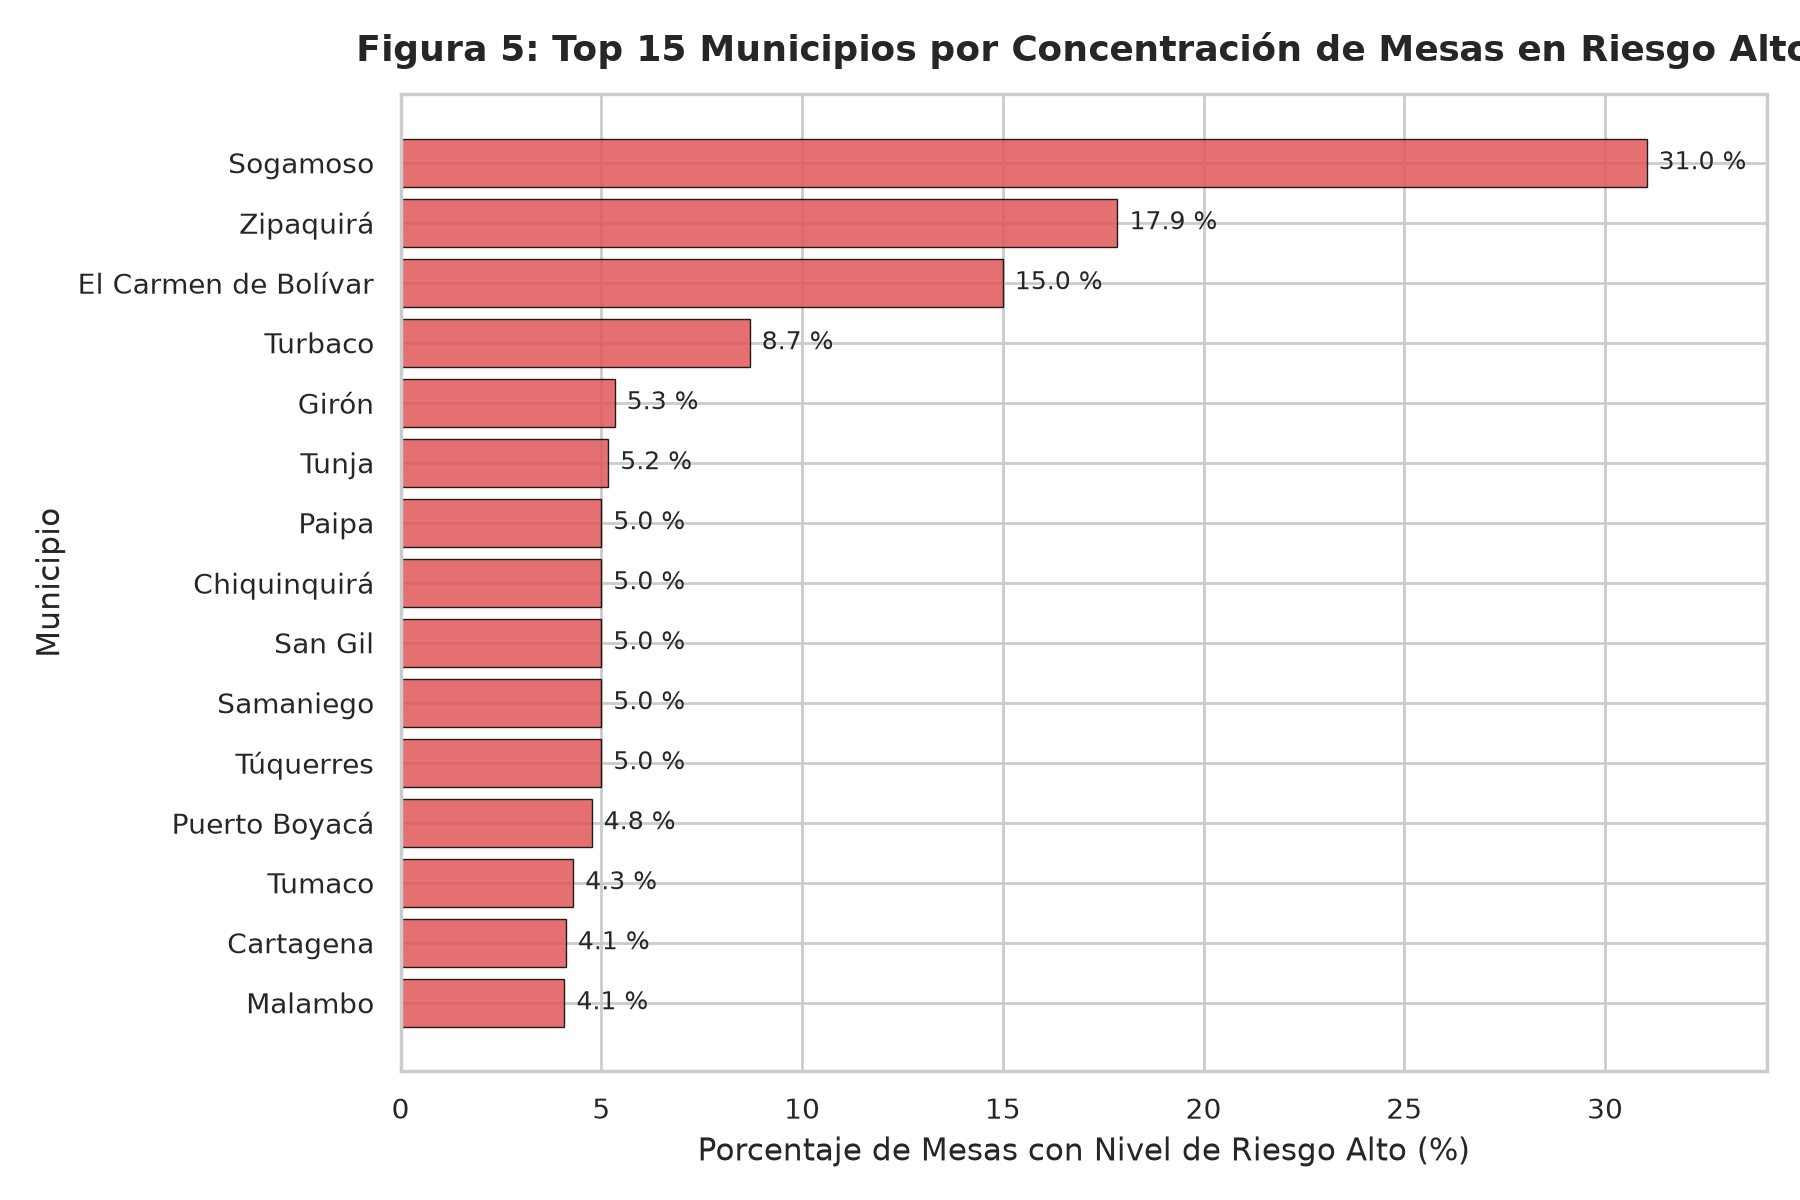

In [5]:
figuras = [
    "fig1_distribucion_participacion.png",
    "fig2_huella_electoral.png",
    "fig3_score_isolation_forest.png",
    "fig4_recall_por_tipo.png",
    "fig5_riesgo_por_municipio.png"
]
for f in figuras:
    print(f"=== {f} ===")
    display(Image(filename=str(OUTPUTS_FIG_DIR / f)))


## 6. Top 5 Mesas más Sospechosas y Explicación en Detalle

In [6]:
top_5 = tablas['top_15'].head(5)
display(top_5)

mesa_ejemplo = top_5.iloc[0]
print("\n--- EXPLICACIÓN DE LA MESA #1 PRIORIZADA PARA AUDITORÍA ---")
print(f"Mesa ID: {mesa_ejemplo['mesa_id']} en {mesa_ejemplo['municipio']} ({mesa_ejemplo['departamento']})")
print(f"Votantes habilitados: {mesa_ejemplo['votantes_habilitados']} | Total reportado: {mesa_ejemplo['total_votos_reportado']}")
print(f"Participación: {mesa_ejemplo['participacion'] * 100:.2f} % (Sobre-participación física imposible)")
print(f"Nivel de riesgo: {mesa_ejemplo['nivel_riesgo']} (Severidad reglas: {mesa_ejemplo['severidad_reglas']}, Score IF: {mesa_ejemplo['score_if']:.4f})")
print(f"Tipo real inyectado (Ground Truth): {mesa_ejemplo['tipo_anomalia']}")
print("Acción recomendada: Apertura inmediata del sobre electoral para recuento manual papeleta por papeleta.")

,ranking,mesa_id,departamento,municipio,zona,total_votos_reportado,votantes_habilitados,participacion,diferencia_aritmetica,pct_max_candidato,pct_nulos,frac_multiplos_10,nivel_riesgo,severidad_reglas,puntaje_reglas,score_if,alerta_reglas,alerta_if,es_anomalia,tipo_anomalia
195,1,M00196,Antioquia,Medellín,rural,81,84,0.964286,44,0.594595,0.000000,0.25,alto,critica,5,0.657551,True,True,1,inconsistencia_aritmetica
1637,2,M01638,Atlántico,Soledad,rural,159,124,1.282258,0,0.489933,0.018868,0.00,alto,critica,5,0.598422,True,True,1,sobre_participacion
287,3,M00288,Antioquia,Medellín,urbana,479,418,1.145933,0,0.668132,0.018789,0.00,alto,critica,5,0.592634,True,True,1,sobre_participacion
4842,4,M04843,Valle del Cauca,Buenaventura,rural,198,161,1.229814,0,0.353535,0.000000,0.25,alto,critica,5,0.588451,True,True,1,sobre_participacion
1823,5,M01824,Atlántico,Malambo,urbana,424,356,1.191011,0,0.524510,0.014151,0.00,alto,critica,5,0.561418,True,True,1,sobre_participacion



--- EXPLICACIÓN DE LA MESA #1 PRIORIZADA PARA AUDITORÍA ---
Mesa ID: M00196 en Medellín (Antioquia)
Votantes habilitados: 84 | Total reportado: 81
Participación: 96.43 % (Sobre-participación física imposible)
Nivel de riesgo: alto (Severidad reglas: critica, Score IF: 0.6576)
Tipo real inyectado (Ground Truth): inconsistencia_aritmetica
Acción recomendada: Apertura inmediata del sobre electoral para recuento manual papeleta por papeleta.
